<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1: System Hardware and Environment Inspection

The system environment determines the performance of deep-learning inference.

In this step, we inspect:
- Operating system
- Python version
- PyTorch version
- CPU information
- RAM capacity
- GPU availability
- CUDA version

This information helps us understand the hardware resources available for inference.

In [1]:
import platform
import os
import torch
import psutil

print("=" * 50)
print("SYSTEM ENVIRONMENT INFORMATION")
print("=" * 50)

# Operating system
print("Operating System:", platform.system())
print("OS Version:", platform.version())

# Python version
print("Python Version:", platform.python_version())

# PyTorch version
print("PyTorch Version:", torch.__version__)

# CPU information
print("CPU:", platform.processor())
print("CPU Cores:", os.cpu_count())

# RAM information
ram = psutil.virtual_memory()
print("Total RAM:", round(ram.total / (1024**3), 2), "GB")
print("Available RAM:", round(ram.available / (1024**3), 2), "GB")

# GPU information
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("CUDA Version:", torch.version.cuda)
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")
else:
    print("GPU: Not available")

SYSTEM ENVIRONMENT INFORMATION
Operating System: Linux
OS Version: #1 SMP Thu Oct 22 03:07:54 UTC 2026
Python Version: 3.13.18
PyTorch Version: 2.14.1+cpu
CPU: x86_64
CPU Cores: 2
Total RAM: 12.67 GB
Available RAM: 11.51 GB
CUDA Available: False
GPU: Not available


## Step 2: System Resource Monitoring

Monitor CPU utilization, RAM usage, and GPU utilization before inference.

These measurements establish the baseline system load and help identify resource bottlenecks during model execution.

In [2]:
import psutil
import torch
import time

# CPU utilization
cpu_usage = psutil.cpu_percent(interval=1)

# RAM utilization
ram = psutil.virtual_memory()

print("CPU Usage:", cpu_usage, "%")
print("RAM Usage:", ram.percent, "%")
print("RAM Available:", round(ram.available / (1024**3), 2), "GB")

# GPU monitoring
if torch.cuda.is_available():
    print("\nGPU Device:", torch.cuda.get_device_name(0))
    print("Allocated GPU Memory:",
          round(torch.cuda.memory_allocated() / (1024**2), 2), "MB")
    print("Reserved GPU Memory:",
          round(torch.cuda.memory_reserved() / (1024**2), 2), "MB")
else:
    print("\nGPU monitoring unavailable: CPU-only runtime.")

CPU Usage: 2.0 %
RAM Usage: 10.2 %
RAM Available: 11.37 GB

GPU monitoring unavailable: CPU-only runtime.


## Step 3: CNN Model Creation

Create a Convolutional Neural Network (CNN) using PyTorch.

The model contains convolutional, ReLU, pooling, and fully connected layers to process image inputs and generate predictions.

In [3]:
import torch
import torch.nn as nn

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Create model
model = CNNModel()

# Display model
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())

print("\nTotal Parameters:", total_params)
print("Model Created Successfully!")

CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total Parameters: 268650
Model Created Successfully!


## Step 4: Synthetic Input Data Generation

Generate random RGB image tensors with dimensions 32 × 32.

The batch size controls the number of images processed in one inference operation. Synthetic data allows performance testing without downloading a dataset.

In [4]:
import torch

# Set random seed for reproducibility
torch.manual_seed(42)

# Define batch size
batch_size = 32

# Generate synthetic RGB images
input_data = torch.randn(batch_size, 3, 32, 32)

print("Input Data Shape:", input_data.shape)
print("Batch Size:", batch_size)
print("Number of Images:", input_data.shape[0])
print("Channels:", input_data.shape[1])
print("Image Height:", input_data.shape[2])
print("Image Width:", input_data.shape[3])
print("Data Type:", input_data.dtype)

Input Data Shape: torch.Size([32, 3, 32, 32])
Batch Size: 32
Number of Images: 32
Channels: 3
Image Height: 32
Image Width: 32
Data Type: torch.float32


## Step 5: CPU and GPU Device Configuration

Select the available execution device using CUDA availability.

Move the CNN model and input tensors to the selected device and disable gradient calculations using evaluation mode and inference mode to reduce unnecessary computation.

In [5]:
import copy
import torch

# Select available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Prepare CPU model
cpu_model = copy.deepcopy(model).to("cpu")
cpu_model.eval()

# Prepare CPU input
cpu_input = input_data.to("cpu")

# Prepare GPU model and input if CUDA is available
if torch.cuda.is_available():
    gpu_model = copy.deepcopy(model).to("cuda")
    gpu_model.eval()

    gpu_input = input_data.to("cuda")

    print("GPU model prepared successfully!")
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Input Device:", gpu_input.device)
else:
    gpu_model = None
    gpu_input = None

    print("GPU unavailable. GPU inference will be skipped.")

print("\nCPU Model Device:", next(cpu_model.parameters()).device)
print("CPU Input Device:", cpu_input.device)
print("Selected Device:", device)
print("Model Evaluation Mode:", not model.training)

GPU unavailable. GPU inference will be skipped.

CPU Model Device: cpu
CPU Input Device: cpu
Selected Device: cpu
Model Evaluation Mode: False


## Step 6: CPU Inference Execution

Execute the CNN model on the CPU using synthetic image inputs.

Inference mode disables gradient tracking and reduces unnecessary computation. The model produces class scores for each input image.

In [6]:
import torch

# Execute CPU inference
with torch.inference_mode():
    cpu_predictions = cpu_model(cpu_input)

# Display results
print("CPU Inference Completed Successfully!")
print("Input Shape:", cpu_input.shape)
print("Output Shape:", cpu_predictions.shape)
print("CPU Device:", cpu_predictions.device)

# Predicted classes
predicted_classes = torch.argmax(cpu_predictions, dim=1)

print("\nPredicted Classes:", predicted_classes[:10])
print("Total Predictions:", len(predicted_classes))

CPU Inference Completed Successfully!
Input Shape: torch.Size([32, 3, 32, 32])
Output Shape: torch.Size([32, 10])
CPU Device: cpu

Predicted Classes: tensor([6, 6, 7, 7, 6, 6, 6, 7, 7, 6])
Total Predictions: 32


## Step 7: GPU Inference Execution

Execute CNN inference using CUDA when an NVIDIA GPU is available.

The model and input tensors are transferred to GPU memory before execution. CUDA synchronization ensures that GPU computations finish before results are displayed.

In [7]:
import torch

if torch.cuda.is_available():

    # Synchronize GPU before execution
    torch.cuda.synchronize()

    # Execute GPU inference
    with torch.inference_mode():
        gpu_predictions = gpu_model(gpu_input)

    # Synchronize after execution
    torch.cuda.synchronize()

    print("GPU Inference Completed Successfully!")
    print("Input Shape:", gpu_input.shape)
    print("Output Shape:", gpu_predictions.shape)
    print("GPU Device:", gpu_predictions.device)

    # Predicted classes
    gpu_classes = torch.argmax(gpu_predictions, dim=1)

    print("\nPredicted Classes:", gpu_classes[:10])
    print("Total Predictions:", len(gpu_classes))

else:
    print("GPU Inference Skipped!")
    print("CUDA is not available in this runtime.")
    print("CPU inference was completed successfully.")

GPU Inference Skipped!
CUDA is not available in this runtime.
CPU inference was completed successfully.


## Step 8: Inference Latency Measurement

Measure the time required to execute one inference batch on CPU and GPU.

Perform warm-up runs to reduce initialization overhead. Use repeated measurements to calculate average latency. CUDA synchronization ensures accurate GPU timing.

In [8]:
import time
import torch
import numpy as np

# Measurement settings
warmup_runs = 5
measurement_runs = 50

# ---------------- CPU LATENCY ----------------

# Warm-up
with torch.inference_mode():
    for _ in range(warmup_runs):
        cpu_model(cpu_input)

# Measure CPU inference
cpu_times = []

with torch.inference_mode():
    for _ in range(measurement_runs):
        start = time.perf_counter()

        cpu_model(cpu_input)

        end = time.perf_counter()
        cpu_times.append((end - start) * 1000)

# CPU statistics
cpu_avg_latency = np.mean(cpu_times)
cpu_median_latency = np.median(cpu_times)

print("CPU Inference Latency")
print("--------------------")
print("Average:", round(cpu_avg_latency, 3), "ms")
print("Median:", round(cpu_median_latency, 3), "ms")


# ---------------- GPU LATENCY ----------------

if torch.cuda.is_available():

    # Warm-up
    with torch.inference_mode():
        for _ in range(warmup_runs):
            gpu_model(gpu_input)

    torch.cuda.synchronize()

    # Measure GPU inference
    gpu_times = []

    with torch.inference_mode():
        for _ in range(measurement_runs):
            torch.cuda.synchronize()

            start = time.perf_counter()

            gpu_model(gpu_input)

            torch.cuda.synchronize()
            end = time.perf_counter()

            gpu_times.append((end - start) * 1000)

    # GPU statistics
    gpu_avg_latency = np.mean(gpu_times)
    gpu_median_latency = np.median(gpu_times)

    print("\nGPU Inference Latency")
    print("--------------------")
    print("Average:", round(gpu_avg_latency, 3), "ms")
    print("Median:", round(gpu_median_latency, 3), "ms")

else:
    gpu_times = []
    gpu_avg_latency = None
    gpu_median_latency = None

    print("\nGPU latency measurement skipped: CUDA unavailable.")

CPU Inference Latency
--------------------
Average: 22.355 ms
Median: 20.2 ms

GPU latency measurement skipped: CUDA unavailable.


## Step 9: Inference Throughput Measurement

Calculate inference throughput in images per second using the measured average latency.

Throughput indicates the processing capacity of the inference system. CPU and GPU throughput are compared to evaluate performance.

In [9]:
# Calculate CPU throughput
cpu_throughput = batch_size / (cpu_avg_latency / 1000)

print("CPU Throughput:", round(cpu_throughput, 2), "images/second")

# Calculate GPU throughput if available
if gpu_avg_latency is not None:

    gpu_throughput = batch_size / (gpu_avg_latency / 1000)

    print("GPU Throughput:", round(gpu_throughput, 2), "images/second")

else:
    gpu_throughput = None
    print("GPU Throughput: Not measured (CUDA unavailable)")

CPU Throughput: 1431.42 images/second
GPU Throughput: Not measured (CUDA unavailable)


## Step 10: CPU and GPU Performance Comparison

Compare average inference latency and throughput between CPU and GPU.

Calculate speedup using the ratio of CPU latency to GPU latency. The comparison identifies the faster execution device for the tested workload.

In [10]:
import pandas as pd

# Create comparison results
comparison = {
    "Metric": ["Average Latency (ms)", "Throughput (images/sec)"],
    "CPU": [cpu_avg_latency, cpu_throughput],
    "GPU": [
        gpu_avg_latency if gpu_avg_latency is not None else "Unavailable",
        gpu_throughput if gpu_throughput is not None else "Unavailable"
    ]
}

comparison_df = pd.DataFrame(comparison)

print("CPU vs GPU Performance Comparison")
print("=" * 40)
display(comparison_df)

# Calculate speedup
if gpu_avg_latency is not None:
    speedup = cpu_avg_latency / gpu_avg_latency

    print("\nInference Speedup:", round(speedup, 2), "x")

    if speedup > 1:
        print("GPU is faster for this workload.")
    elif speedup < 1:
        print("CPU is faster for this workload.")
    else:
        print("CPU and GPU have similar latency.")
else:
    speedup = None
    print("\nGPU comparison unavailable.")
    print("Only CPU inference measurements are available.")

CPU vs GPU Performance Comparison


,Metric,CPU,GPU
0,Average Latency (ms),22.355373,Unavailable
1,Throughput (images/sec),1431.423248,Unavailable



GPU comparison unavailable.
Only CPU inference measurements are available.


## Step 11: Bottleneck Identification and Visualization

Visualize inference latency and throughput using bar charts.

Analyze CPU performance, batch processing efficiency, memory usage, and GPU availability to identify potential system-level bottlenecks.

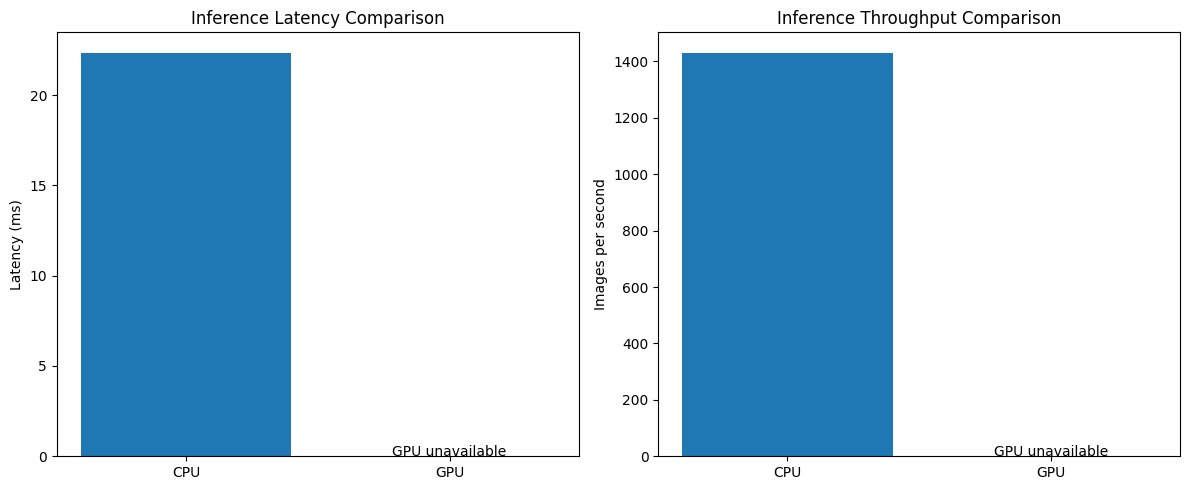

SYSTEM BOTTLENECK ANALYSIS
CPU Utilization: 37.0 %
RAM Utilization: 12.2 %
CPU Latency: 22.355 ms
CPU Throughput: 1431.42 images/sec
GPU Availability: False

Potential Bottlenecks:
- CPU utilization is not critically high during this sample.
- RAM utilization is not critically high.
- GPU acceleration unavailable.
- Inference is limited to CPU execution.


In [11]:
import matplotlib.pyplot as plt
import psutil
import numpy as np

# Performance metrics
labels = ["CPU", "GPU"]
latency_values = [
    cpu_avg_latency,
    gpu_avg_latency if gpu_avg_latency is not None else 0
]

throughput_values = [
    cpu_throughput,
    gpu_throughput if gpu_throughput is not None else 0
]

# Create visualizations
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Latency comparison
axes[0].bar(labels, latency_values)
axes[0].set_title("Inference Latency Comparison")
axes[0].set_ylabel("Latency (ms)")
axes[0].text(1, 0, "GPU unavailable", ha="center")

# Throughput comparison
axes[1].bar(labels, throughput_values)
axes[1].set_title("Inference Throughput Comparison")
axes[1].set_ylabel("Images per second")
axes[1].text(1, 0, "GPU unavailable", ha="center")

plt.tight_layout()
plt.show()

# System bottleneck analysis
cpu_load = psutil.cpu_percent(interval=1)
memory_usage = psutil.virtual_memory().percent

print("SYSTEM BOTTLENECK ANALYSIS")
print("=" * 40)

print("CPU Utilization:", cpu_load, "%")
print("RAM Utilization:", memory_usage, "%")
print("CPU Latency:", round(cpu_avg_latency, 3), "ms")
print("CPU Throughput:", round(cpu_throughput, 2), "images/sec")
print("GPU Availability:", torch.cuda.is_available())

print("\nPotential Bottlenecks:")

if cpu_load > 80:
    print("- High CPU utilization detected.")
else:
    print("- CPU utilization is not critically high during this sample.")

if memory_usage > 80:
    print("- High RAM utilization detected.")
else:
    print("- RAM utilization is not critically high.")

if not torch.cuda.is_available():
    print("- GPU acceleration unavailable.")
    print("- Inference is limited to CPU execution.")

## Step 12: Final Inference Performance Report

Generate a summary report containing system configuration, model details, inference latency, throughput, GPU availability, and bottleneck observations.

Save the report in JSON format for documentation and further analysis.

In [12]:
import json
import os
import torch
import platform

# Create final report
performance_report = {
    "Skill": "Skill 8 - GPU Inference Execution Path and System-Level Bottleneck Identification",
    "Model": "CNN",
    "Input Shape": list(input_data.shape),
    "Batch Size": batch_size,
    "Execution Device": str(device),
    "CPU Latency (ms)": round(float(cpu_avg_latency), 3),
    "CPU Throughput (images/sec)": round(float(cpu_throughput), 2),
    "GPU Available": torch.cuda.is_available(),
    "GPU Latency (ms)": (
        round(float(gpu_avg_latency), 3)
        if gpu_avg_latency is not None else None
    ),
    "GPU Throughput (images/sec)": (
        round(float(gpu_throughput), 2)
        if gpu_throughput is not None else None
    ),
    "GPU Speedup": (
        round(float(speedup), 2)
        if speedup is not None else None
    ),
    "CPU Utilization (%)": cpu_load,
    "RAM Utilization (%)": memory_usage,
    "PyTorch Version": torch.__version__,
    "Operating System": platform.platform(),
    "Bottleneck": (
        "GPU unavailable; inference executed using CPU"
        if not torch.cuda.is_available()
        else "Performance depends on CPU, GPU, memory and workload"
    )
}

# Create output directory
output_dir = "/content/Skill8_Results"
os.makedirs(output_dir, exist_ok=True)

# Save report as JSON
report_file = os.path.join(output_dir, "inference_performance_report.json")

with open(report_file, "w") as file:
    json.dump(performance_report, file, indent=4)

# Display report
print("=" * 55)
print("FINAL INFERENCE PERFORMANCE REPORT")
print("=" * 55)

for key, value in performance_report.items():
    print(f"{key}: {value}")

print("\nReport saved successfully!")
print("Location:", report_file)

FINAL INFERENCE PERFORMANCE REPORT
Skill: Skill 8 - GPU Inference Execution Path and System-Level Bottleneck Identification
Model: CNN
Input Shape: [32, 3, 32, 32]
Batch Size: 32
Execution Device: cpu
CPU Latency (ms): 22.355
CPU Throughput (images/sec): 1431.42
GPU Available: False
GPU Latency (ms): None
GPU Throughput (images/sec): None
GPU Speedup: None
CPU Utilization (%): 37.0
RAM Utilization (%): 12.2
PyTorch Version: 2.14.1+cpu
Operating System: Linux-6.6.159+-x86_64-with-glibc2.39
Bottleneck: GPU unavailable; inference executed using CPU

Report saved successfully!
Location: /content/Skill8_Results/inference_performance_report.json
